# Reinforcement Learning: Resolviendo Laberintos

## Q-Learning, SARSA, DQN y Policy Gradient en Laberintos Complejos

**Objetivo**: Aplicar técnicas de Reinforcement Learning para resolver laberintos
de complejidad creciente — desde Q-Learning tabular hasta Deep RL con redes neuronales.

## El Entorno: Generador de Laberintos

Crearemos un generador de laberintos usando el algoritmo **Recursive Backtracking**
(DFS aleatorio), que produce laberintos perfectos (un único camino entre dos puntos).

### Elementos del laberinto:
- `░` = Camino libre
- `█` = Pared
- `S` = Inicio (Start)
- `G` = Meta (Goal)
- `A` = Agente
- `T` = Trampa (recompensa negativa)
- `K` = Llave (recompensa intermedia)

### Acciones: 4 direcciones
- 0: Arriba (↑)
- 1: Derecha (→)
- 2: Abajo (↓)
- 3: Izquierda (←)

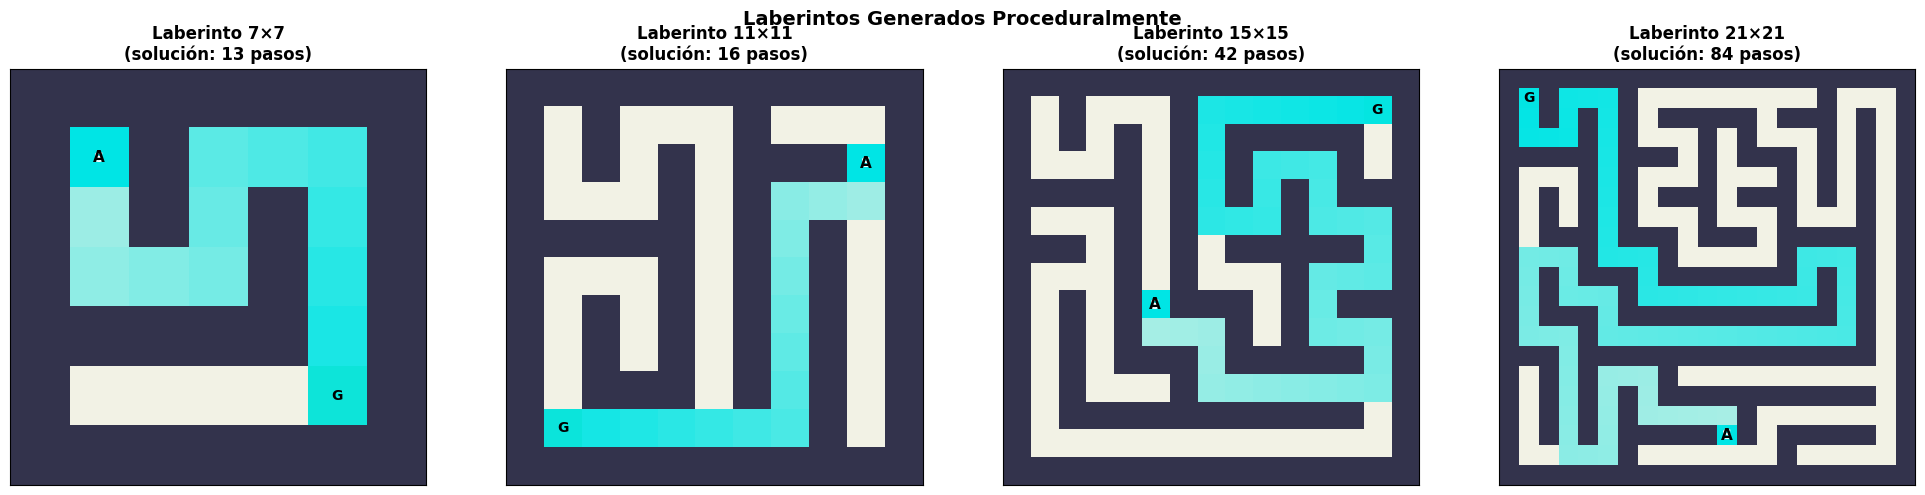

✅ Generador de laberintos funcional
   - Recursive Backtracking genera laberintos perfectos
   - BFS encuentra la solución óptima para comparar


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from collections import deque
import time
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

# =============================================================================
# GENERADOR DE LABERINTOS
# =============================================================================

class Laberinto:
    """
    Entorno de laberinto para Reinforcement Learning.

    Genera laberintos proceduralmente usando Recursive Backtracking (DFS).
    Compatible con la interfaz gym: reset(), step(action), render().

    Grid:
        0 = camino libre
        1 = pared
        2 = inicio (S)
        3 = meta (G)
        4 = trampa (T)
        5 = llave/bonus (K)
    """

    LIBRE = 0
    PARED = 1
    INICIO = 2
    META = 3
    TRAMPA = 4
    BONUS = 5

    ACCIONES = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}  # ↑ → ↓ ←
    ACCION_NOMBRES = {0: '↑', 1: '→', 2: '↓', 3: '←'}

    def __init__(self, filas=7, columnas=7, trampas=0, bonus=0, seed=None):
        """
        Args:
            filas: alto del laberinto (debe ser impar)
            columnas: ancho del laberinto (debe ser impar)
            trampas: número de trampas
            bonus: número de bonus/llaves
        """
        self.filas = filas if filas % 2 == 1 else filas + 1
        self.columnas = columnas if columnas % 2 == 1 else columnas + 1
        self.n_trampas = trampas
        self.n_bonus = bonus
        self.rng = np.random.RandomState(seed)

        self.grid = None
        self.pos_inicio = None
        self.pos_meta = None
        self.pos_agente = None
        self.bonus_recogidos = set()
        self.pasos = 0
        self.max_pasos = self.filas * self.columnas * 2

        self._generar_laberinto()

    def _generar_laberinto(self):
        """Genera un laberinto perfecto usando Recursive Backtracking (DFS)."""
        f, c = self.filas, self.columnas
        self.grid = np.ones((f, c), dtype=int)  # Todo paredes

        # DFS desde (1,1)
        stack = [(1, 1)]
        self.grid[1, 1] = self.LIBRE

        while stack:
            r, col = stack[-1]
            vecinos = []

            for dr, dc in [(-2, 0), (2, 0), (0, -2), (0, 2)]:
                nr, nc = r + dr, col + dc
                if 1 <= nr < f-1 and 1 <= nc < c-1 and self.grid[nr, nc] == self.PARED:
                    vecinos.append((nr, nc, r + dr//2, col + dc//2))

            if vecinos:
                nr, nc, wr, wc = vecinos[self.rng.randint(len(vecinos))]
                self.grid[wr, wc] = self.LIBRE  # Romper pared intermedia
                self.grid[nr, nc] = self.LIBRE
                stack.append((nr, nc))
            else:
                stack.pop()

        # Colocar inicio y meta
        celdas_libres = list(zip(*np.where(self.grid == self.LIBRE)))
        self.rng.shuffle(celdas_libres)

        self.pos_inicio = celdas_libres[0]
        # Meta: lo más lejos posible del inicio
        distancias = [abs(c[0]-self.pos_inicio[0]) + abs(c[1]-self.pos_inicio[1])
                     for c in celdas_libres]
        self.pos_meta = celdas_libres[np.argmax(distancias)]

        self.grid[self.pos_inicio] = self.INICIO
        self.grid[self.pos_meta] = self.META

        # Colocar trampas y bonus en celdas libres restantes
        celdas_disponibles = [c for c in celdas_libres
                             if c != self.pos_inicio and c != self.pos_meta]
        self.rng.shuffle(celdas_disponibles)

        for i in range(min(self.n_trampas, len(celdas_disponibles))):
            self.grid[celdas_disponibles[i]] = self.TRAMPA

        for i in range(self.n_trampas, min(self.n_trampas + self.n_bonus, len(celdas_disponibles))):
            self.grid[celdas_disponibles[i]] = self.BONUS

    def reset(self):
        """Reinicia el entorno. Devuelve el estado inicial."""
        self.pos_agente = self.pos_inicio
        self.bonus_recogidos = set()
        self.pasos = 0
        return self._get_estado()

    def _get_estado(self):
        """Estado = posición del agente como entero."""
        return self.pos_agente[0] * self.columnas + self.pos_agente[1]

    def _get_estado_vector(self):
        """Estado como vector (para DQN): posición normalizada + grid local."""
        r, c = self.pos_agente
        # Vista local 5x5 alrededor del agente
        vista = np.zeros((5, 5))
        for dr in range(-2, 3):
            for dc in range(-2, 3):
                nr, nc = r + dr, c + dc
                if 0 <= nr < self.filas and 0 <= nc < self.columnas:
                    vista[dr+2, dc+2] = self.grid[nr, nc]
                else:
                    vista[dr+2, dc+2] = 1  # Fuera del mapa = pared

        # Dirección a la meta (normalizada)
        dr_meta = (self.pos_meta[0] - r) / self.filas
        dc_meta = (self.pos_meta[1] - c) / self.columnas

        return np.concatenate([
            [r / self.filas, c / self.columnas],  # Posición normalizada
            [dr_meta, dc_meta],                     # Dirección a meta
            vista.flatten()                          # Vista local 5x5
        ]).astype(np.float32)

    def step(self, accion):
        """
        Ejecuta una acción.

        Returns:
            next_state, reward, done, info
        """
        self.pasos += 1
        dr, dc = self.ACCIONES[accion]
        nr, nc = self.pos_agente[0] + dr, self.pos_agente[1] + dc

        reward = -0.1  # Penalización por paso (incentivar eficiencia)
        done = False
        info = {'evento': 'paso'}

        # Verificar si el movimiento es válido
        if 0 <= nr < self.filas and 0 <= nc < self.columnas and self.grid[nr, nc] != self.PARED:
            self.pos_agente = (nr, nc)

            celda = self.grid[nr, nc]

            if celda == self.META:
                reward = 10.0
                done = True
                info['evento'] = 'meta'
            elif celda == self.TRAMPA:
                reward = -5.0
                done = True
                info['evento'] = 'trampa'
            elif celda == self.BONUS and (nr, nc) not in self.bonus_recogidos:
                reward = 2.0
                self.bonus_recogidos.add((nr, nc))
                info['evento'] = 'bonus'
        else:
            reward = -0.5  # Penalización por chocar con pared
            info['evento'] = 'pared'

        # Timeout
        if self.pasos >= self.max_pasos:
            done = True
            info['evento'] = 'timeout'

        return self._get_estado(), reward, done, info

    @property
    def n_estados(self):
        return self.filas * self.columnas

    @property
    def n_acciones(self):
        return 4

    def render(self, ax=None, titulo="", camino=None):
        """Visualiza el laberinto."""
        if ax is None:
            fig, ax = plt.subplots(figsize=(8, 8))

        # Crear imagen coloreada
        img = np.zeros((self.filas, self.columnas, 3))

        for r in range(self.filas):
            for c in range(self.columnas):
                if self.grid[r, c] == self.PARED:
                    img[r, c] = [0.2, 0.2, 0.3]       # Gris oscuro
                elif self.grid[r, c] == self.LIBRE:
                    img[r, c] = [0.95, 0.95, 0.9]      # Beige claro
                elif self.grid[r, c] == self.INICIO:
                    img[r, c] = [0.3, 0.7, 0.3]        # Verde
                elif self.grid[r, c] == self.META:
                    img[r, c] = [1.0, 0.84, 0.0]       # Dorado
                elif self.grid[r, c] == self.TRAMPA:
                    img[r, c] = [0.8, 0.2, 0.2]        # Rojo
                elif self.grid[r, c] == self.BONUS:
                    img[r, c] = [0.3, 0.5, 0.9]        # Azul

        # Agente
        if self.pos_agente:
            r, c = self.pos_agente
            img[r, c] = [0.0, 0.9, 0.9]  # Cyan

        # Camino recorrido
        if camino:
            for i, (r, c) in enumerate(camino):
                alpha = 0.3 + 0.7 * (i / len(camino))
                img[r, c] = [alpha * 0.0 + (1-alpha) * img[r,c,0],
                             alpha * 0.9 + (1-alpha) * img[r,c,1],
                             alpha * 0.9 + (1-alpha) * img[r,c,2]]

        ax.imshow(img, interpolation='nearest')
        ax.set_title(titulo, fontsize=12, fontweight='bold')
        ax.set_xticks([])
        ax.set_yticks([])

        # Leyenda
        for r in range(self.filas):
            for c in range(self.columnas):
                if self.grid[r, c] == self.INICIO:
                    ax.text(c, r, 'S', ha='center', va='center', fontsize=10, fontweight='bold', color='white')
                elif self.grid[r, c] == self.META:
                    ax.text(c, r, 'G', ha='center', va='center', fontsize=10, fontweight='bold', color='black')
                elif self.grid[r, c] == self.TRAMPA:
                    ax.text(c, r, 'T', ha='center', va='center', fontsize=9, fontweight='bold', color='white')
                elif self.grid[r, c] == self.BONUS:
                    ax.text(c, r, 'K', ha='center', va='center', fontsize=9, fontweight='bold', color='white')
                if self.pos_agente and (r, c) == self.pos_agente:
                    ax.text(c, r, 'A', ha='center', va='center', fontsize=11, fontweight='bold', color='black')

    def resolver_bfs(self):
        """Resuelve el laberinto con BFS (solución óptima)."""
        inicio = self.pos_inicio
        meta = self.pos_meta

        queue = deque([(inicio, [inicio])])
        visitados = {inicio}

        while queue:
            (r, c), camino = queue.popleft()

            if (r, c) == meta:
                return camino

            for dr, dc in self.ACCIONES.values():
                nr, nc = r + dr, c + dc
                if (0 <= nr < self.filas and 0 <= nc < self.columnas and
                    (nr, nc) not in visitados and self.grid[nr, nc] != self.PARED):
                    visitados.add((nr, nc))
                    queue.append(((nr, nc), camino + [(nr, nc)]))

        return None

# --- Demostración ---
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

tamanios = [(7, 7), (11, 11), (15, 15), (21, 21)]
for i, (f, c) in enumerate(tamanios):
    maze = Laberinto(f, c, seed=42)
    maze.reset()
    solucion = maze.resolver_bfs()
    maze.render(axes[i], titulo=f'Laberinto {f}×{c}\n(solución: {len(solucion)} pasos)',
                camino=solucion)

plt.suptitle('Laberintos Generados Proceduralmente', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("✅ Generador de laberintos funcional")
print("   - Recursive Backtracking genera laberintos perfectos")
print("   - BFS encuentra la solución óptima para comparar")

## Q-Learning Tabular

### Repaso del algoritmo

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right]$$

- **Off-policy**: usa el máximo Q para actualizar (no la acción realmente tomada)
- **ε-greedy**: explora con probabilidad ε, explota con probabilidad 1-ε

In [2]:
# =============================================================================
# Q-LEARNING TABULAR
# =============================================================================

class QLearningAgent:
    """
    Agente Q-Learning tabular para laberintos.
    """

    def __init__(self, n_estados, n_acciones, alpha=0.1, gamma=0.99,
                 epsilon=1.0, epsilon_min=0.01, epsilon_decay=0.995):
        self.n_estados = n_estados
        self.n_acciones = n_acciones
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay

        # Tabla Q inicializada en ceros
        self.Q = np.zeros((n_estados, n_acciones))

        # Estadísticas
        self.rewards_por_episodio = []
        self.pasos_por_episodio = []
        self.exitos = []

    def seleccionar_accion(self, estado):
        """ε-greedy policy."""
        if np.random.random() < self.epsilon:
            return np.random.randint(self.n_acciones)
        return np.argmax(self.Q[estado])

    def actualizar(self, estado, accion, reward, next_estado, done):
        """Actualización Q-Learning."""
        if done:
            target = reward
        else:
            target = reward + self.gamma * np.max(self.Q[next_estado])

        # TD update
        self.Q[estado, accion] += self.alpha * (target - self.Q[estado, accion])

    def entrenar(self, env, n_episodios=1000, verbose=True):
        """Entrena el agente en el entorno."""
        for ep in range(n_episodios):
            estado = env.reset()
            total_reward = 0
            pasos = 0
            done = False

            while not done:
                accion = self.seleccionar_accion(estado)
                next_estado, reward, done, info = env.step(accion)
                self.actualizar(estado, accion, reward, next_estado, done)

                estado = next_estado
                total_reward += reward
                pasos += 1

            self.rewards_por_episodio.append(total_reward)
            self.pasos_por_episodio.append(pasos)
            self.exitos.append(1 if info['evento'] == 'meta' else 0)

            # Decay epsilon
            self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

            if verbose and (ep + 1) % (n_episodios // 5) == 0:
                ultimos = self.rewards_por_episodio[-100:]
                tasa_exito = np.mean(self.exitos[-100:]) * 100
                print(f"  Ep {ep+1:5d} | Reward: {np.mean(ultimos):7.2f} | "
                      f"Éxito: {tasa_exito:5.1f}% | ε: {self.epsilon:.4f}")

    def resolver(self, env, max_pasos=500):
        """Resuelve el laberinto usando la política aprendida (greedy)."""
        estado = env.reset()
        camino = [env.pos_agente]
        total_reward = 0

        for _ in range(max_pasos):
            accion = np.argmax(self.Q[estado])  # Greedy
            estado, reward, done, info = env.step(accion)
            camino.append(env.pos_agente)
            total_reward += reward

            if done:
                break

        return camino, total_reward, info['evento']

    def visualizar_politica(self, env, ax=None):
        """Dibuja las flechas de la política aprendida sobre el laberinto."""
        if ax is None:
            fig, ax = plt.subplots(figsize=(8, 8))

        env.reset()
        env.render(ax, titulo='Política Aprendida (Q-Learning)')

        flechas = {0: (0, -0.3), 1: (0.3, 0), 2: (0, 0.3), 3: (-0.3, 0)}

        for r in range(env.filas):
            for c in range(env.columnas):
                if env.grid[r, c] not in [env.PARED, env.META]:
                    estado = r * env.columnas + c
                    if np.any(self.Q[estado] != 0):
                        accion = np.argmax(self.Q[estado])
                        dx, dy = flechas[accion]
                        ax.annotate('', xy=(c + dx, r + dy), xytext=(c, r),
                                   arrowprops=dict(arrowstyle='->', color='red', lw=1.5))

# --- Entrenar Q-Learning en laberinto 7×7 ---
print("=" * 60)
print("Q-LEARNING EN LABERINTO 7×7")
print("=" * 60)

maze_7 = Laberinto(7, 7, seed=42)
agent_q = QLearningAgent(maze_7.n_estados, maze_7.n_acciones,
                         alpha=0.2, gamma=0.99, epsilon=1.0, epsilon_decay=0.998)

agent_q.entrenar(maze_7, n_episodios=2000)

# Resolver
camino_q, reward_q, evento_q = agent_q.resolver(maze_7)
solucion_optima = maze_7.resolver_bfs()

print(f"\n📊 Resultado:")
print(f"  Evento: {evento_q}")
print(f"  Pasos del agente: {len(camino_q)}")
print(f"  Solución óptima (BFS): {len(solucion_optima)}")
print(f"  Eficiencia: {len(solucion_optima)/len(camino_q)*100:.1f}%")

Q-LEARNING EN LABERINTO 7×7
  Ep   400 | Reward:    5.21 | Éxito: 100.0% | ε: 0.4490
  Ep   800 | Reward:    7.85 | Éxito: 100.0% | ε: 0.2016
  Ep  1200 | Reward:    8.46 | Éxito: 100.0% | ε: 0.0905
  Ep  1600 | Reward:    8.75 | Éxito: 100.0% | ε: 0.0406
  Ep  2000 | Reward:    8.81 | Éxito: 100.0% | ε: 0.0182

📊 Resultado:
  Evento: meta
  Pasos del agente: 13
  Solución óptima (BFS): 13
  Eficiencia: 100.0%


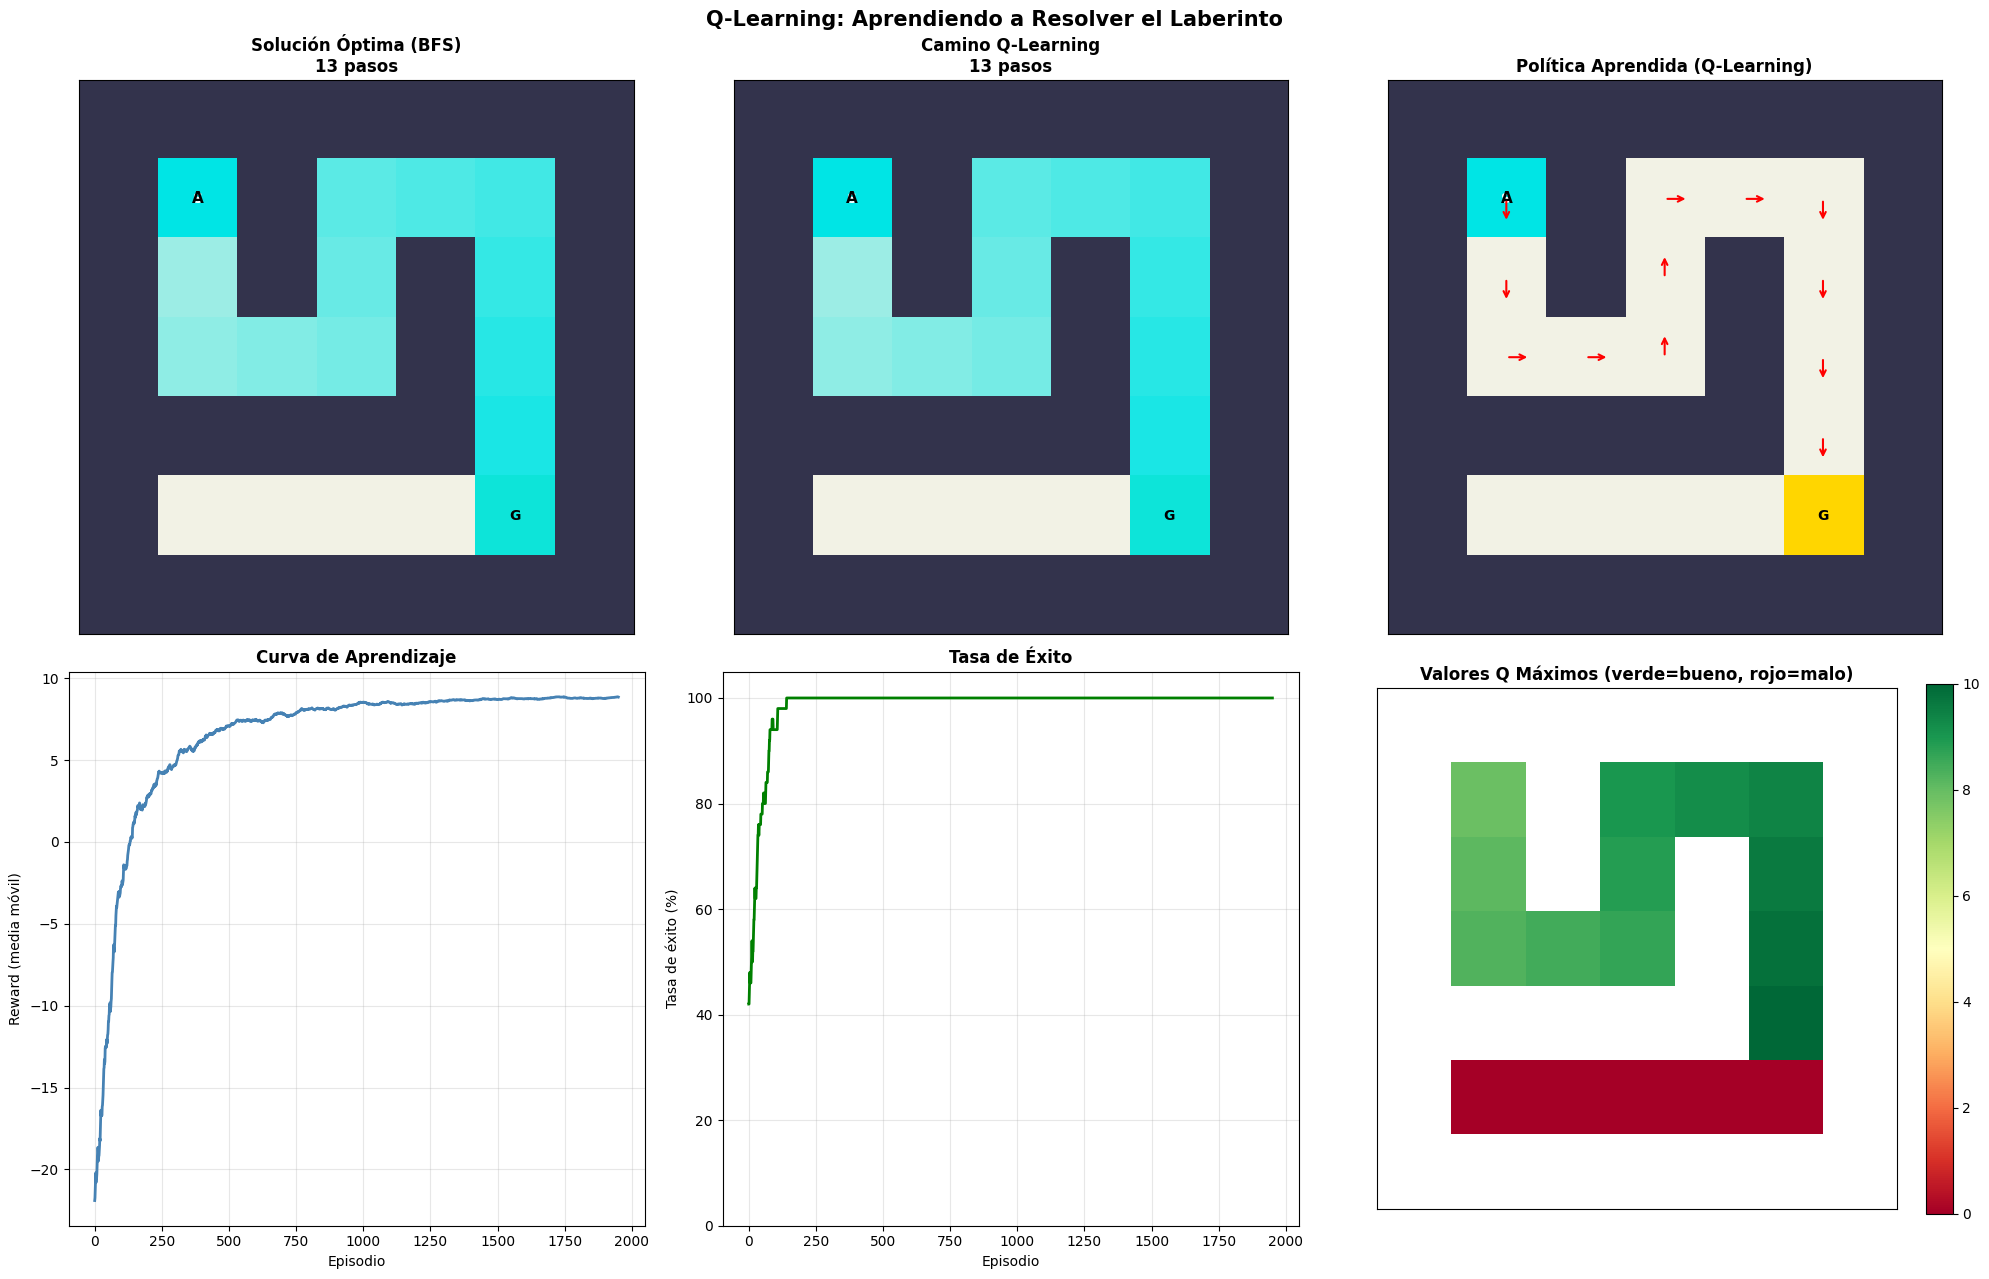

In [4]:
# --- Visualización completa del Q-Learning ---
fig, axes = plt.subplots(2, 3, figsize=(20, 13))

# 1. Laberinto con solución BFS
maze_7.reset()
maze_7.render(axes[0, 0], titulo=f'Solución Óptima (BFS)\n{len(solucion_optima)} pasos',
              camino=solucion_optima)

# 2. Camino del agente Q-Learning
maze_7.reset()
maze_7.render(axes[0, 1], titulo=f'Camino Q-Learning\n{len(camino_q)} pasos',
              camino=camino_q)

# 3. Política aprendida
agent_q.visualizar_politica(maze_7, axes[0, 2])

# 4. Curva de recompensa
window = 50
rewards_smooth = np.convolve(agent_q.rewards_por_episodio,
                             np.ones(window)/window, mode='valid')
axes[1, 0].plot(rewards_smooth, linewidth=2, color='steelblue')
axes[1, 0].set_xlabel('Episodio')
axes[1, 0].set_ylabel('Reward (media móvil)')
axes[1, 0].set_title('Curva de Aprendizaje', fontsize=12, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# 5. Tasa de éxito
exito_smooth = np.convolve(agent_q.exitos, np.ones(window)/window, mode='valid') * 100
axes[1, 1].plot(exito_smooth, linewidth=2, color='green')
axes[1, 1].set_xlabel('Episodio')
axes[1, 1].set_ylabel('Tasa de éxito (%)')
axes[1, 1].set_title('Tasa de Éxito', fontsize=12, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_ylim(0, 105)

# 6. Mapa de calor de max Q-values
q_values = np.max(agent_q.Q, axis=1).reshape(maze_7.filas, maze_7.columnas)
q_masked = np.ma.masked_where(maze_7.grid == maze_7.PARED, q_values)
im = axes[1, 2].imshow(q_masked, cmap='RdYlGn', interpolation='nearest')
axes[1, 2].set_title('Valores Q Máximos (verde=bueno, rojo=malo)', fontsize=12, fontweight='bold')
axes[1, 2].set_xticks([])
axes[1, 2].set_yticks([])
plt.colorbar(im, ax=axes[1, 2], fraction=0.046)

plt.suptitle('Q-Learning: Aprendiendo a Resolver el Laberinto', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## SARSA: On-Policy vs Off-Policy

### Diferencia con Q-Learning

| | Q-Learning (Off-policy) | SARSA (On-policy) |
|---|---|---|
| **Actualización** | $Q(s,a) + \alpha[r + \gamma \max_{a'} Q(s',a') - Q(s,a)]$ | $Q(s,a) + \alpha[r + \gamma Q(s',a') - Q(s,a)]$ |
| **Usa** | El máximo Q del siguiente estado | La acción **realmente tomada** en el siguiente estado |
| **Comportamiento** | Optimista (asume lo mejor) | Conservador (considera exploración) |
| **En laberintos con trampas** | Puede ser arriesgado | Más seguro, evita trampas |

Q-LEARNING vs SARSA EN LABERINTO CON TRAMPAS

Q-Learning:
  Ep   600 | Reward:   -5.08 | Éxito:   0.0% | ε: 0.1649
  Ep  1200 | Reward:   -5.01 | Éxito:   0.0% | ε: 0.0272
  Ep  1800 | Reward:   -5.00 | Éxito:   0.0% | ε: 0.0100
  Ep  2400 | Reward:   -5.00 | Éxito:   0.0% | ε: 0.0100
  Ep  3000 | Reward:   -5.00 | Éxito:   0.0% | ε: 0.0100

SARSA:
  Ep   600 | Reward:   -5.09 | Éxito:   0.0%
  Ep  1200 | Reward:   -5.00 | Éxito:   0.0%
  Ep  1800 | Reward:   -5.00 | Éxito:   0.0%
  Ep  2400 | Reward:   -5.00 | Éxito:   0.0%
  Ep  3000 | Reward:   -5.00 | Éxito:   0.0%


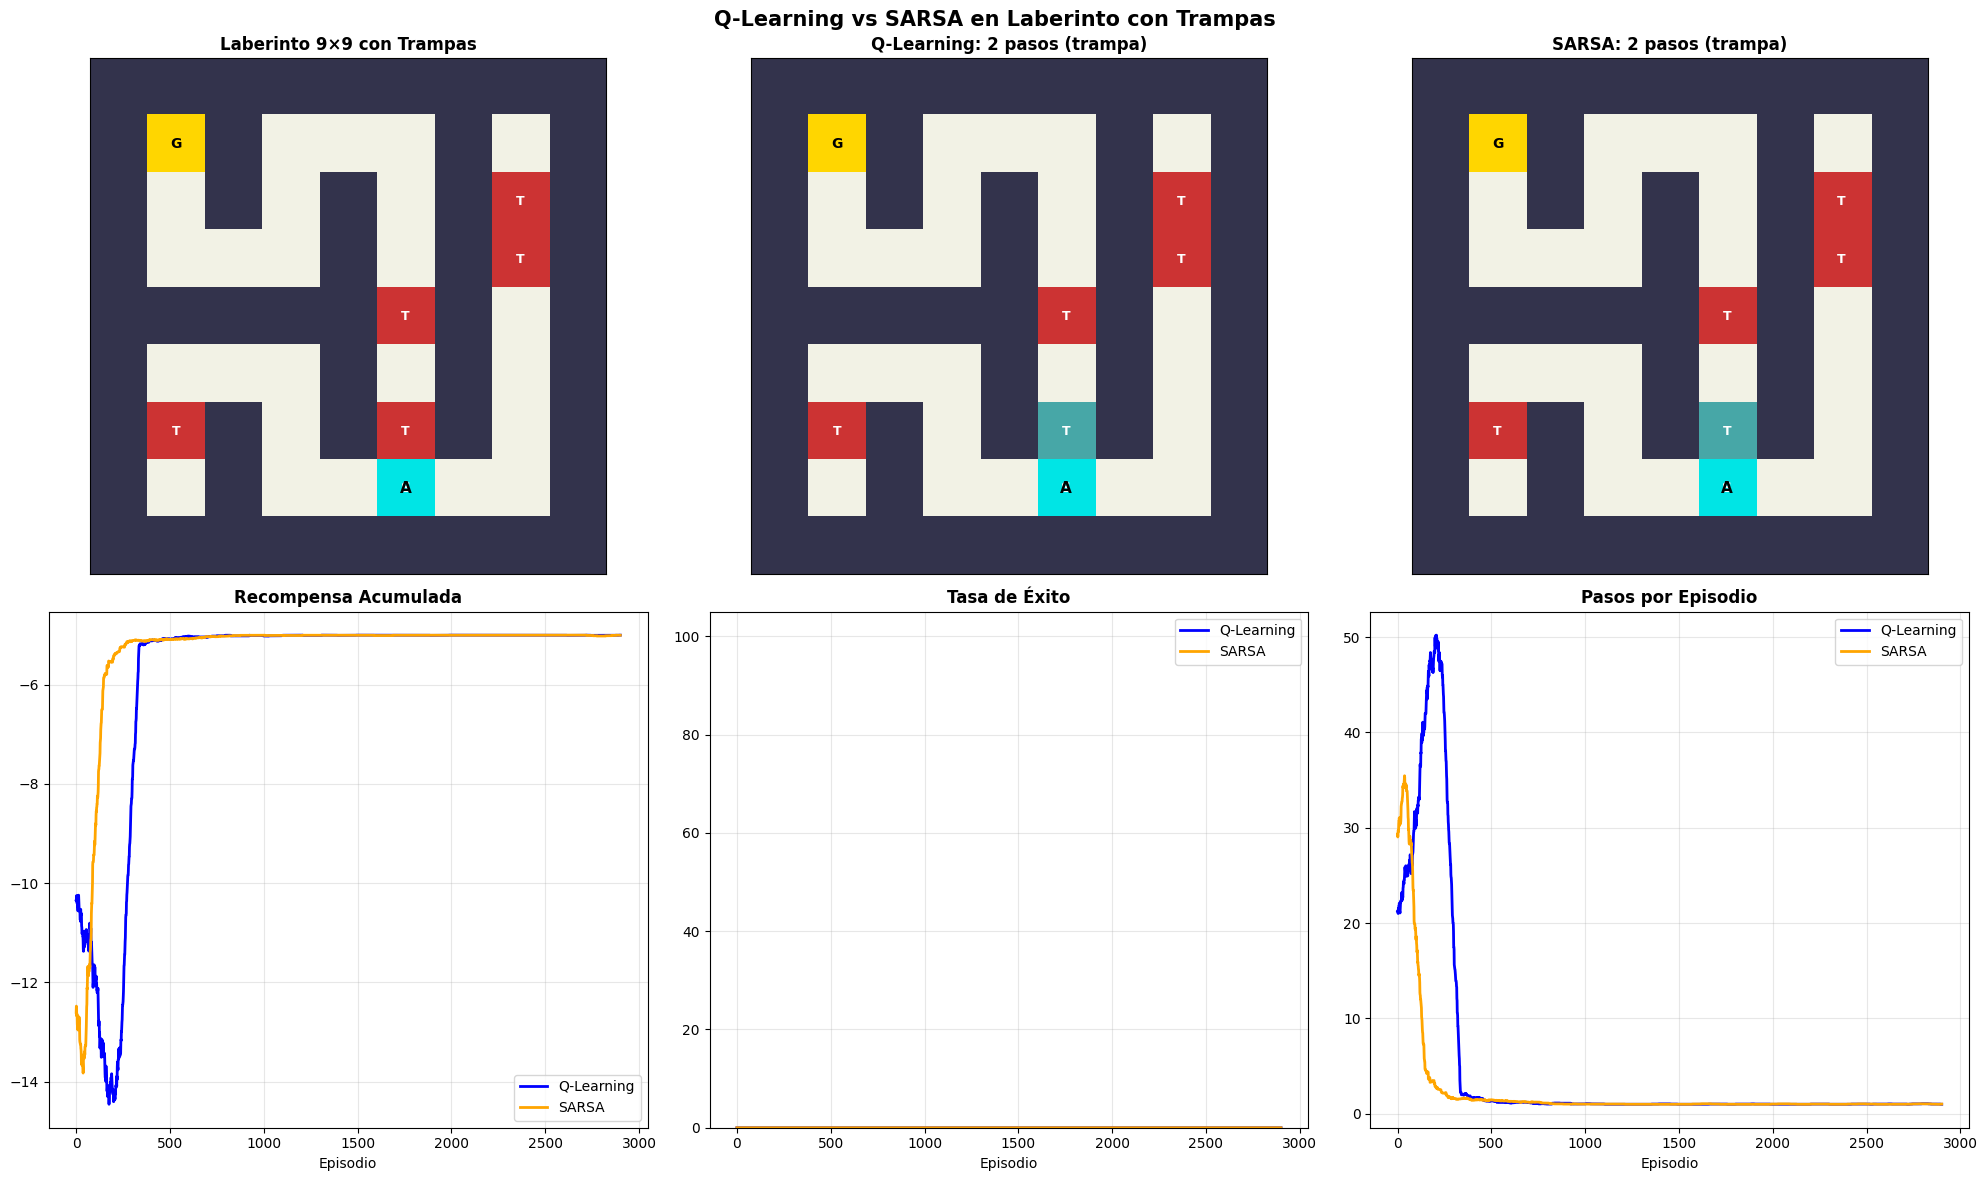


💡 En laberintos con trampas:
   - SARSA es más conservador (evita rutas cercanas a trampas)
   - Q-Learning puede encontrar rutas más cortas pero más arriesgadas


In [5]:
# =============================================================================
# SARSA
# =============================================================================

class SARSAAgent:
    """Agente SARSA (on-policy)."""

    def __init__(self, n_estados, n_acciones, alpha=0.1, gamma=0.99,
                 epsilon=1.0, epsilon_min=0.01, epsilon_decay=0.995):
        self.n_estados = n_estados
        self.n_acciones = n_acciones
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.Q = np.zeros((n_estados, n_acciones))
        self.rewards_por_episodio = []
        self.pasos_por_episodio = []
        self.exitos = []

    def seleccionar_accion(self, estado):
        if np.random.random() < self.epsilon:
            return np.random.randint(self.n_acciones)
        return np.argmax(self.Q[estado])

    def entrenar(self, env, n_episodios=1000, verbose=True):
        for ep in range(n_episodios):
            estado = env.reset()
            accion = self.seleccionar_accion(estado)
            total_reward = 0
            pasos = 0
            done = False

            while not done:
                next_estado, reward, done, info = env.step(accion)
                next_accion = self.seleccionar_accion(next_estado)

                # SARSA: usa la acción REALMENTE elegida (on-policy)
                if done:
                    target = reward
                else:
                    target = reward + self.gamma * self.Q[next_estado, next_accion]

                self.Q[estado, accion] += self.alpha * (target - self.Q[estado, accion])

                estado = next_estado
                accion = next_accion
                total_reward += reward
                pasos += 1

            self.rewards_por_episodio.append(total_reward)
            self.pasos_por_episodio.append(pasos)
            self.exitos.append(1 if info['evento'] == 'meta' else 0)
            self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

            if verbose and (ep + 1) % (n_episodios // 5) == 0:
                ultimos = self.rewards_por_episodio[-100:]
                tasa = np.mean(self.exitos[-100:]) * 100
                print(f"  Ep {ep+1:5d} | Reward: {np.mean(ultimos):7.2f} | Éxito: {tasa:5.1f}%")

    def resolver(self, env, max_pasos=500):
        estado = env.reset()
        camino = [env.pos_agente]
        total_reward = 0
        for _ in range(max_pasos):
            accion = np.argmax(self.Q[estado])
            estado, reward, done, info = env.step(accion)
            camino.append(env.pos_agente)
            total_reward += reward
            if done: break
        return camino, total_reward, info['evento']

# --- Comparar Q-Learning vs SARSA en laberinto con trampas ---
print("=" * 60)
print("Q-LEARNING vs SARSA EN LABERINTO CON TRAMPAS")
print("=" * 60)

maze_traps = Laberinto(9, 9, trampas=5, seed=42)

print("\nQ-Learning:")
agent_q2 = QLearningAgent(maze_traps.n_estados, maze_traps.n_acciones,
                          alpha=0.2, gamma=0.99, epsilon_decay=0.997)
agent_q2.entrenar(maze_traps, n_episodios=3000)

print("\nSARSA:")
agent_s = SARSAAgent(maze_traps.n_estados, maze_traps.n_acciones,
                     alpha=0.2, gamma=0.99, epsilon_decay=0.997)
agent_s.entrenar(maze_traps, n_episodios=3000)

# Comparar
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

# Laberinto con trampas
maze_traps.reset()
maze_traps.render(axes[0, 0], titulo='Laberinto 9×9 con Trampas')

# Caminos
camino_q2, _, ev_q = agent_q2.resolver(maze_traps)
maze_traps.reset()
maze_traps.render(axes[0, 1], titulo=f'Q-Learning: {len(camino_q2)} pasos ({ev_q})', camino=camino_q2)

camino_s, _, ev_s = agent_s.resolver(maze_traps)
maze_traps.reset()
maze_traps.render(axes[0, 2], titulo=f'SARSA: {len(camino_s)} pasos ({ev_s})', camino=camino_s)

# Curvas de aprendizaje
w = 100
for data, label, color in [(agent_q2.rewards_por_episodio, 'Q-Learning', 'blue'),
                            (agent_s.rewards_por_episodio, 'SARSA', 'orange')]:
    smooth = np.convolve(data, np.ones(w)/w, mode='valid')
    axes[1, 0].plot(smooth, label=label, linewidth=2, color=color)
axes[1, 0].set_title('Recompensa Acumulada', fontweight='bold')
axes[1, 0].legend(); axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_xlabel('Episodio')

# Tasa de éxito
for data, label, color in [(agent_q2.exitos, 'Q-Learning', 'blue'),
                            (agent_s.exitos, 'SARSA', 'orange')]:
    smooth = np.convolve(data, np.ones(w)/w, mode='valid') * 100
    axes[1, 1].plot(smooth, label=label, linewidth=2, color=color)
axes[1, 1].set_title('Tasa de Éxito', fontweight='bold')
axes[1, 1].legend(); axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_xlabel('Episodio'); axes[1, 1].set_ylim(0, 105)

# Pasos promedio
for data, label, color in [(agent_q2.pasos_por_episodio, 'Q-Learning', 'blue'),
                            (agent_s.pasos_por_episodio, 'SARSA', 'orange')]:
    smooth = np.convolve(data, np.ones(w)/w, mode='valid')
    axes[1, 2].plot(smooth, label=label, linewidth=2, color=color)
axes[1, 2].set_title('Pasos por Episodio', fontweight='bold')
axes[1, 2].legend(); axes[1, 2].grid(True, alpha=0.3)
axes[1, 2].set_xlabel('Episodio')

plt.suptitle('Q-Learning vs SARSA en Laberinto con Trampas', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 En laberintos con trampas:")
print("   - SARSA es más conservador (evita rutas cercanas a trampas)")
print("   - Q-Learning puede encontrar rutas más cortas pero más arriesgadas")

## Deep Q-Network (DQN) para Laberintos Grandes

### ¿Por qué DQN?

Para un laberinto de 21×21 = 441 celdas × 4 acciones = 1,764 entradas en la tabla Q.
Pero para laberintos más grandes o con más información de estado,
necesitamos **generalizar** con una red neuronal.

### Arquitectura

```
Estado (29 dims) → [64] → ReLU → [64] → ReLU → [4] → Q-values
     │                                              │
     ├── Posición (2)                               ├── Q(s, ↑)
     ├── Dir. a meta (2)                            ├── Q(s, →)
     └── Vista local 5×5 (25)                       ├── Q(s, ↓)
                                                    └── Q(s, ←)
```

DQN EN LABERINTO 11×11
Dimensión del estado: 29
Entrenando DQN (state_dim=29)...
  Ep   300 | Reward:    4.22 | Éxito: 100.0% | ε: 0.4060
  Ep   600 | Reward:    7.59 | Éxito: 100.0% | ε: 0.1649
  Ep   900 | Reward:    8.22 | Éxito: 100.0% | ε: 0.0669
  Ep  1200 | Reward:    8.47 | Éxito: 100.0% | ε: 0.0272
  Ep  1500 | Reward:    8.56 | Éxito: 100.0% | ε: 0.0110
  Completado en 113.7s


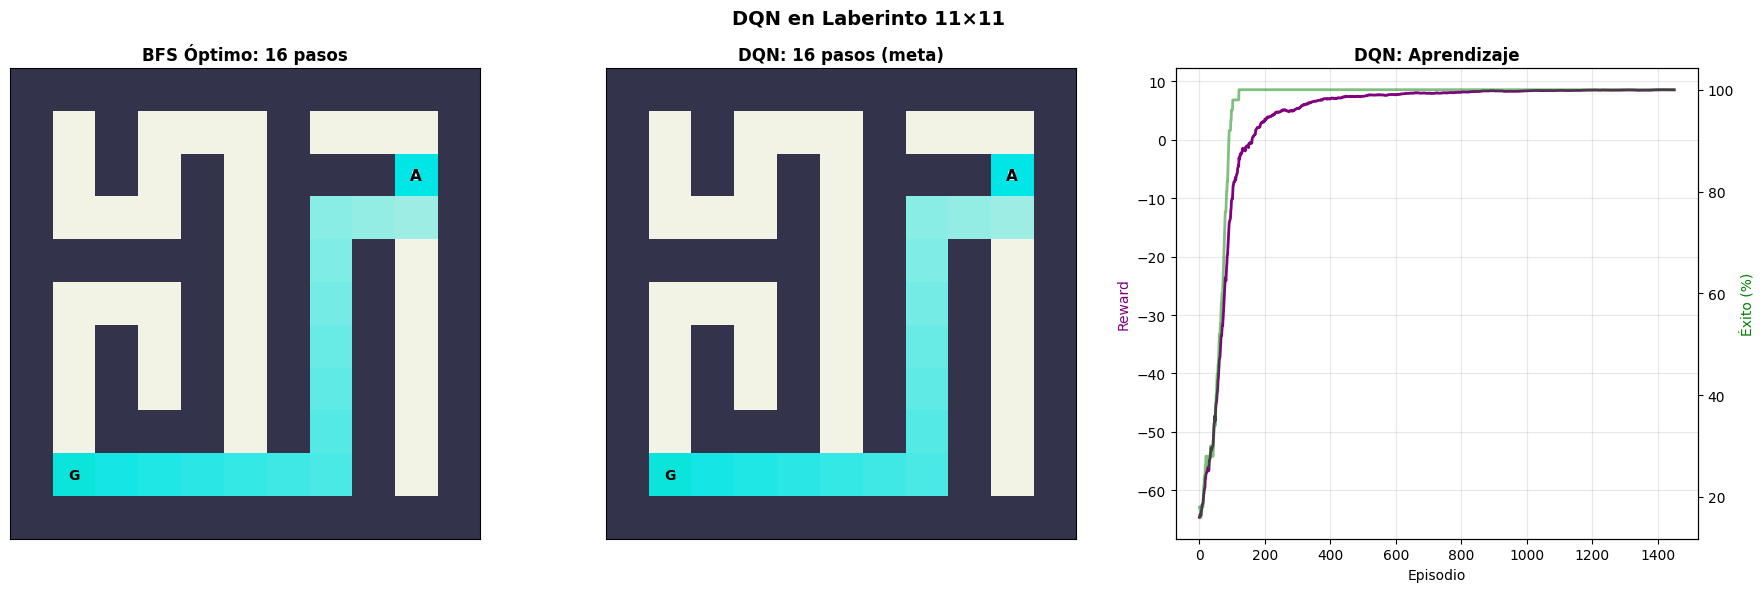

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
import random

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# =============================================================================
# DQN
# =============================================================================

class DQN(nn.Module):
    """Red neuronal para aproximar Q(s, a)."""

    def __init__(self, state_dim, n_actions, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_actions)
        )

    def forward(self, x):
        return self.net(x)

class ReplayBuffer:
    """Memoria de experiencias para DQN."""

    def __init__(self, capacity=10000):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (np.array(states), np.array(actions), np.array(rewards, dtype=np.float32),
                np.array(next_states), np.array(dones, dtype=np.float32))

    def __len__(self):
        return len(self.buffer)

class AgenteDQN:
    """Agente DQN para laberintos."""

    def __init__(self, state_dim, n_actions, lr=1e-3, gamma=0.99,
                 epsilon=1.0, epsilon_min=0.01, epsilon_decay=0.995,
                 batch_size=64, target_update=10):
        self.state_dim = state_dim
        self.n_actions = n_actions
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.batch_size = batch_size
        self.target_update = target_update

        self.q_net = DQN(state_dim, n_actions).to(device)
        self.target_net = DQN(state_dim, n_actions).to(device)
        self.target_net.load_state_dict(self.q_net.state_dict())

        self.optimizer = optim.Adam(self.q_net.parameters(), lr=lr)
        self.memory = ReplayBuffer(10000)

        self.rewards_por_episodio = []
        self.exitos = []

    def seleccionar_accion(self, state):
        if np.random.random() < self.epsilon:
            return np.random.randint(self.n_actions)

        with torch.no_grad():
            state_t = torch.FloatTensor(state).unsqueeze(0).to(device)
            q_values = self.q_net(state_t)
            return q_values.argmax(dim=1).item()

    def _train_step(self):
        if len(self.memory) < self.batch_size:
            return

        states, actions, rewards, next_states, dones = self.memory.sample(self.batch_size)

        states_t = torch.FloatTensor(states).to(device)
        actions_t = torch.LongTensor(actions).to(device)
        rewards_t = torch.FloatTensor(rewards).to(device)
        next_states_t = torch.FloatTensor(next_states).to(device)
        dones_t = torch.FloatTensor(dones).to(device)

        # Q actual
        q_values = self.q_net(states_t).gather(1, actions_t.unsqueeze(1)).squeeze(1)

        # Q target
        with torch.no_grad():
            next_q = self.target_net(next_states_t).max(dim=1)[0]
            targets = rewards_t + self.gamma * next_q * (1 - dones_t)

        loss = nn.MSELoss()(q_values, targets)
        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.q_net.parameters(), 1.0)
        self.optimizer.step()

    def entrenar(self, env, n_episodios=500, verbose=True):
        print(f"Entrenando DQN (state_dim={self.state_dim})...")
        start = time.time()

        for ep in range(n_episodios):
            env.reset()
            state = env._get_estado_vector()
            total_reward = 0
            done = False

            while not done:
                action = self.seleccionar_accion(state)
                _, reward, done, info = env.step(action)
                next_state = env._get_estado_vector()

                self.memory.push(state, action, reward, next_state, done)
                self._train_step()

                state = next_state
                total_reward += reward

            self.rewards_por_episodio.append(total_reward)
            self.exitos.append(1 if info['evento'] == 'meta' else 0)
            self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

            # Actualizar target network
            if (ep + 1) % self.target_update == 0:
                self.target_net.load_state_dict(self.q_net.state_dict())

            if verbose and (ep + 1) % (n_episodios // 5) == 0:
                r_mean = np.mean(self.rewards_por_episodio[-100:])
                tasa = np.mean(self.exitos[-100:]) * 100
                print(f"  Ep {ep+1:5d} | Reward: {r_mean:7.2f} | Éxito: {tasa:5.1f}% | ε: {self.epsilon:.4f}")

        print(f"  Completado en {time.time()-start:.1f}s")

    def resolver(self, env, max_pasos=500):
        env.reset()
        state = env._get_estado_vector()
        camino = [env.pos_agente]
        total_reward = 0

        for _ in range(max_pasos):
            with torch.no_grad():
                state_t = torch.FloatTensor(state).unsqueeze(0).to(device)
                action = self.q_net(state_t).argmax(dim=1).item()

            _, reward, done, info = env.step(action)
            state = env._get_estado_vector()
            camino.append(env.pos_agente)
            total_reward += reward
            if done: break

        return camino, total_reward, info['evento']

# --- DQN en laberinto 11×11 ---
print("=" * 60)
print("DQN EN LABERINTO 11×11")
print("=" * 60)

maze_11 = Laberinto(11, 11, seed=42)
maze_11.reset() # Add this line to initialize pos_agente
state_dim = len(maze_11._get_estado_vector())
print(f"Dimensión del estado: {state_dim}")

agent_dqn = AgenteDQN(state_dim, 4, lr=5e-4, epsilon_decay=0.997)
agent_dqn.entrenar(maze_11, n_episodios=1500)

camino_dqn, _, ev_dqn = agent_dqn.resolver(maze_11)
sol_11 = maze_11.resolver_bfs()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

maze_11.reset()
maze_11.render(axes[0], titulo=f'BFS Óptimo: {len(sol_11)} pasos', camino=sol_11)

maze_11.reset()
maze_11.render(axes[1], titulo=f'DQN: {len(camino_dqn)} pasos ({ev_dqn})', camino=camino_dqn)

# Curva de aprendizaje
w = 50
smooth = np.convolve(agent_dqn.rewards_por_episodio, np.ones(w)/w, mode='valid')
axes[2].plot(smooth, linewidth=2, color='purple')
exito_s = np.convolve(agent_dqn.exitos, np.ones(w)/w, mode='valid') * 100
ax2 = axes[2].twinx()
ax2.plot(exito_s, linewidth=2, color='green', alpha=0.5)
ax2.set_ylabel('Éxito (%)', color='green')
axes[2].set_xlabel('Episodio')
axes[2].set_ylabel('Reward', color='purple')
axes[2].set_title('DQN: Aprendizaje', fontsize=12, fontweight='bold')
axes[2].grid(True, alpha=0.3)

plt.suptitle('DQN en Laberinto 11×11', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Policy Gradient (REINFORCE)

### Diferencia con Q-Learning/DQN

| Q-Learning / DQN | Policy Gradient |
|---|---|
| Aprende Q(s,a) → valor | Aprende π(a|s) → política directamente |
| Política derivada de Q | Política parametrizada con red neuronal |
| Determinista (argmax) | Estocástica (muestreo de probabilidades) |

### Algoritmo REINFORCE

$$\nabla_\theta J(\theta) = \mathbb{E}\left[\sum_t \nabla_\theta \log \pi_\theta(a_t|s_t) \cdot G_t\right]$$

Donde $G_t = \sum_{k=t}^{T} \gamma^{k-t} r_k$ es el retorno acumulado.

POLICY GRADIENT (REINFORCE) EN LABERINTO 11×11
Entrenando REINFORCE...
  Ep   400 | Reward:  -54.86 | Éxito:  17.0%
  Ep   800 | Reward:  -25.80 | Éxito:   0.0%
  Ep  1200 | Reward:  -24.88 | Éxito:   0.0%
  Ep  1600 | Reward:  -28.88 | Éxito:   0.0%
  Ep  2000 | Reward:  -24.46 | Éxito:   0.0%
  Completado en 441.5s


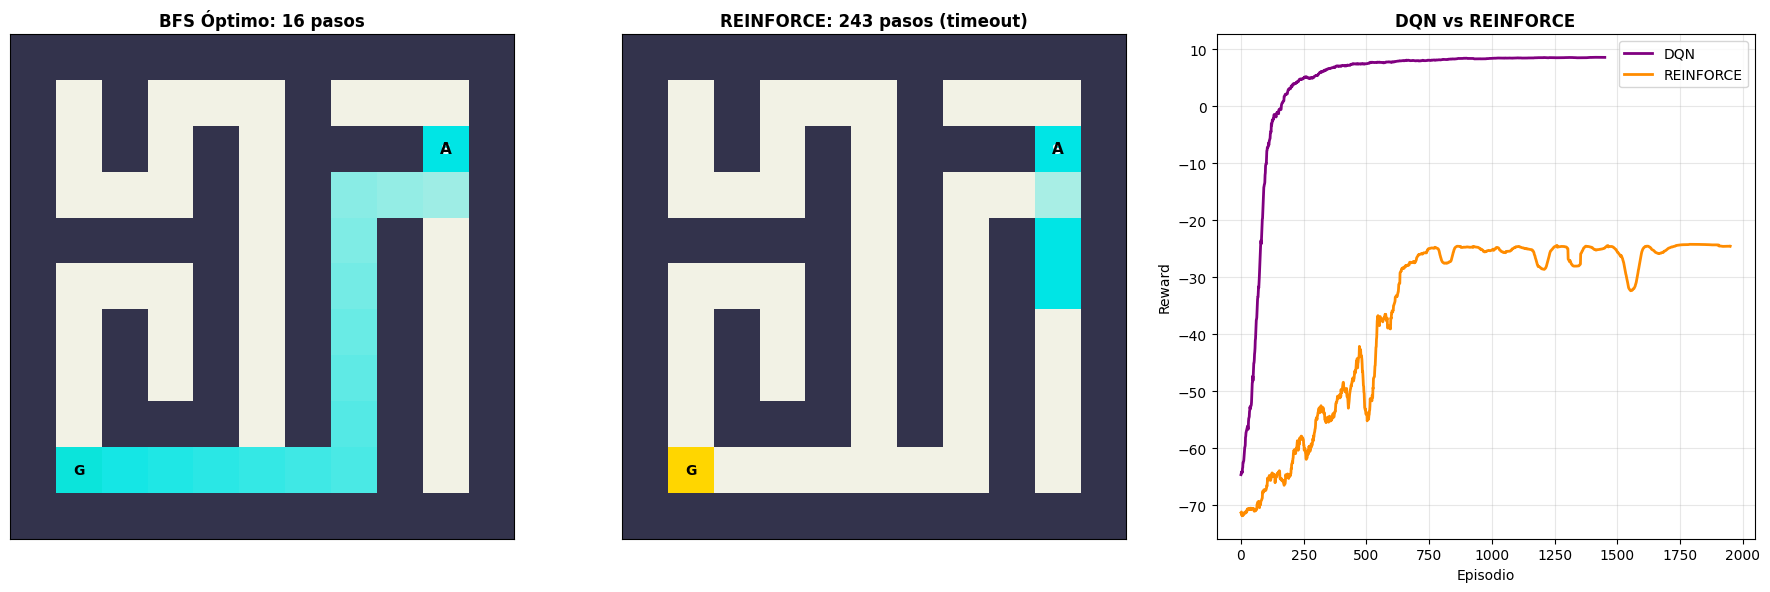

In [8]:
# =============================================================================
# POLICY GRADIENT (REINFORCE)
# =============================================================================

class PolicyNetwork(nn.Module):
    """Red de política: estado → P(acción)."""

    def __init__(self, state_dim, n_actions, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_actions),
            nn.Softmax(dim=-1)
        )

    def forward(self, x):
        return self.net(x)

class AgentePolicyGradient:
    """Agente REINFORCE para laberintos."""

    def __init__(self, state_dim, n_actions, lr=1e-3, gamma=0.99):
        self.gamma = gamma
        self.policy = PolicyNetwork(state_dim, n_actions).to(device)
        self.optimizer = optim.Adam(self.policy.parameters(), lr=lr)

        self.rewards_por_episodio = []
        self.exitos = []

    def seleccionar_accion(self, state):
        state_t = torch.FloatTensor(state).unsqueeze(0).to(device)
        probs = self.policy(state_t)
        dist = torch.distributions.Categorical(probs)
        action = dist.sample()
        return action.item(), dist.log_prob(action)

    def entrenar(self, env, n_episodios=1000, verbose=True):
        print("Entrenando REINFORCE...")
        start = time.time()

        for ep in range(n_episodios):
            env.reset()
            state = env._get_estado_vector()

            log_probs = []
            rewards = []
            done = False

            while not done:
                action, log_prob = self.seleccionar_accion(state)
                _, reward, done, info = env.step(action)
                state = env._get_estado_vector()

                log_probs.append(log_prob)
                rewards.append(reward)

            # Calcular retornos descontados
            returns = []
            G = 0
            for r in reversed(rewards):
                G = r + self.gamma * G
                returns.insert(0, G)

            returns = torch.FloatTensor(returns).to(device)
            returns = (returns - returns.mean()) / (returns.std() + 1e-8)  # Normalizar

            # Actualizar política
            policy_loss = []
            for log_prob, G in zip(log_probs, returns):
                policy_loss.append(-log_prob * G)

            self.optimizer.zero_grad()
            torch.stack(policy_loss).sum().backward()
            self.optimizer.step()

            self.rewards_por_episodio.append(sum(rewards))
            self.exitos.append(1 if info['evento'] == 'meta' else 0)

            if verbose and (ep + 1) % (n_episodios // 5) == 0:
                r_mean = np.mean(self.rewards_por_episodio[-100:])
                tasa = np.mean(self.exitos[-100:]) * 100
                print(f"  Ep {ep+1:5d} | Reward: {r_mean:7.2f} | Éxito: {tasa:5.1f}%")

        print(f"  Completado en {time.time()-start:.1f}s")

    def resolver(self, env, max_pasos=500):
        self.policy.eval()
        env.reset()
        state = env._get_estado_vector()
        camino = [env.pos_agente]
        total_reward = 0

        for _ in range(max_pasos):
            with torch.no_grad():
                state_t = torch.FloatTensor(state).unsqueeze(0).to(device)
                probs = self.policy(state_t)
                action = probs.argmax(dim=1).item()

            _, reward, done, info = env.step(action)
            state = env._get_estado_vector()
            camino.append(env.pos_agente)
            total_reward += reward
            if done: break

        self.policy.train()
        return camino, total_reward, info['evento']

# --- Entrenar REINFORCE ---
print("=" * 60)
print("POLICY GRADIENT (REINFORCE) EN LABERINTO 11×11")
print("=" * 60)

agent_pg = AgentePolicyGradient(state_dim, 4, lr=5e-4, gamma=0.99)
agent_pg.entrenar(maze_11, n_episodios=2000)

camino_pg, _, ev_pg = agent_pg.resolver(maze_11)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

maze_11.reset()
maze_11.render(axes[0], titulo=f'BFS Óptimo: {len(sol_11)} pasos', camino=sol_11)

maze_11.reset()
maze_11.render(axes[1], titulo=f'REINFORCE: {len(camino_pg)} pasos ({ev_pg})', camino=camino_pg)

w = 50
for data, label, color in [(agent_dqn.rewards_por_episodio, 'DQN', 'purple'),
                            (agent_pg.rewards_por_episodio, 'REINFORCE', 'darkorange')]:
    smooth = np.convolve(data, np.ones(w)/w, mode='valid')
    axes[2].plot(smooth, label=label, linewidth=2, color=color)
axes[2].set_title('DQN vs REINFORCE', fontweight='bold')
axes[2].legend(); axes[2].grid(True, alpha=0.3)
axes[2].set_xlabel('Episodio'); axes[2].set_ylabel('Reward')

plt.tight_layout()
plt.show()

## Desafío: Laberinto con Trampas, Llaves y Bonus

Un laberinto más complejo donde el agente debe:
- Evitar trampas (T) → -5 reward, fin del episodio
- Recoger llaves/bonus (K) → +2 reward
- Llegar a la meta (G) → +10 reward

DESAFÍO: LABERINTO COMPLEJO (13×13 con trampas y bonus)
  Ep  1000 | Reward:   -5.27 | Éxito:   0.0% | ε: 0.2229
  Ep  2000 | Reward:   -5.12 | Éxito:   0.0% | ε: 0.0497
  Ep  3000 | Reward:   -5.12 | Éxito:   0.0% | ε: 0.0111
  Ep  4000 | Reward:   -5.12 | Éxito:   0.0% | ε: 0.0100
  Ep  5000 | Reward:   -5.10 | Éxito:   0.0% | ε: 0.0100
Entrenando DQN (state_dim=29)...
  Ep   400 | Reward:   -8.41 | Éxito:   0.0% | ε: 0.4490
  Ep   800 | Reward:   -6.79 | Éxito:   0.0% | ε: 0.2016
  Ep  1200 | Reward:   -5.17 | Éxito:   0.0% | ε: 0.0905
  Ep  1600 | Reward:   -5.11 | Éxito:   0.0% | ε: 0.0406
  Ep  2000 | Reward:   -5.11 | Éxito:   0.0% | ε: 0.0182
  Completado en 36.1s


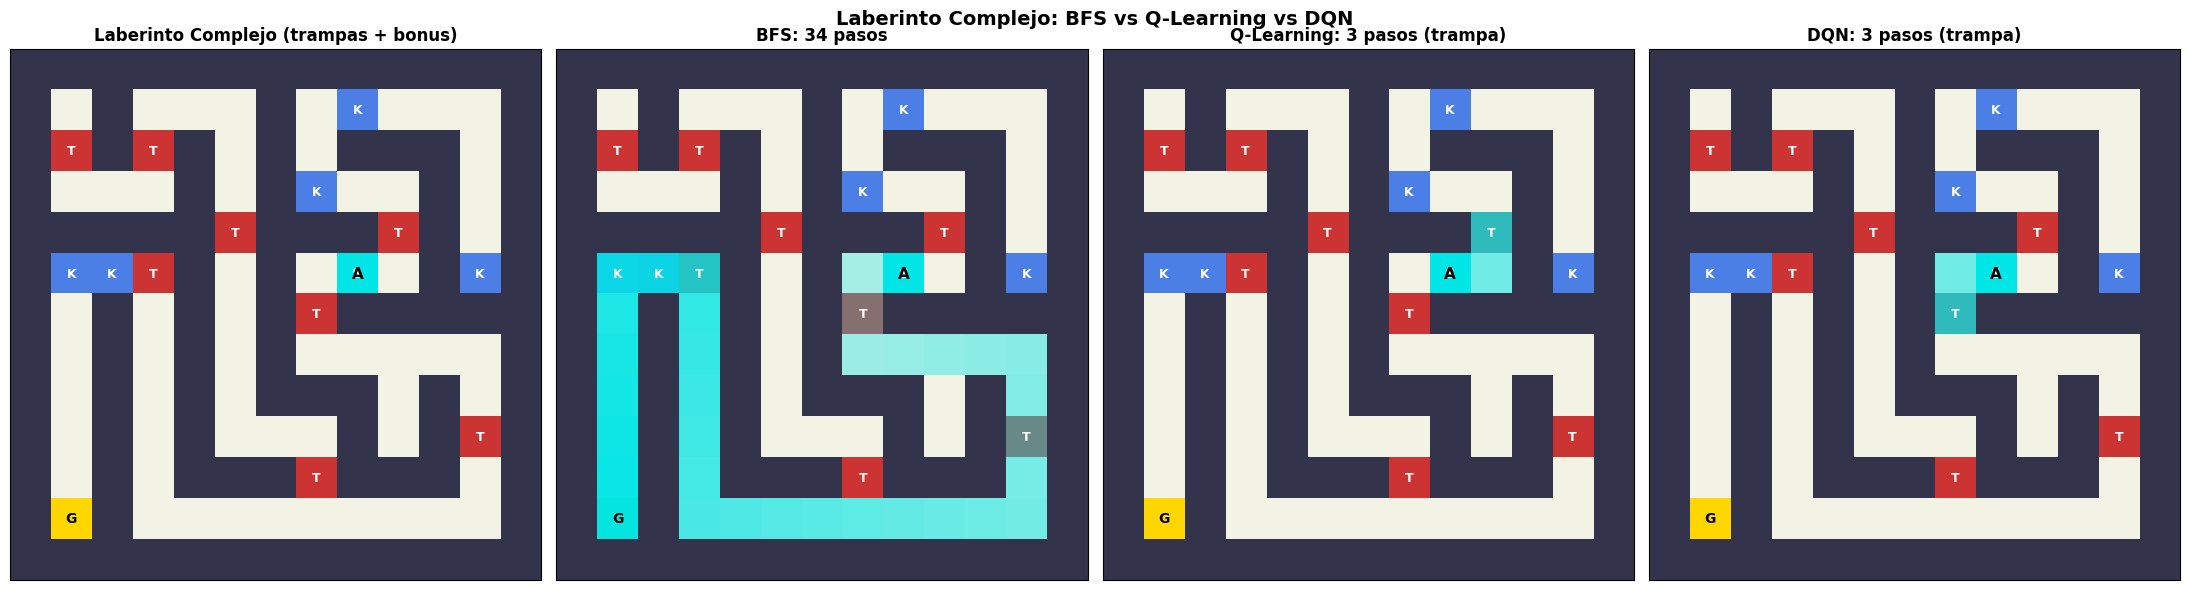

In [11]:
# --- Laberinto complejo ---
print("=" * 60)
print("DESAFÍO: LABERINTO COMPLEJO (13×13 con trampas y bonus)")
print("=" * 60)

maze_complex = Laberinto(13, 13, trampas=8, bonus=5, seed=42)
sol_complex = maze_complex.resolver_bfs()

# Entrenar Q-Learning
agent_complex_q = QLearningAgent(maze_complex.n_estados, 4,
                                  alpha=0.15, gamma=0.99, epsilon_decay=0.9985)
agent_complex_q.entrenar(maze_complex, n_episodios=5000)

# Entrenar DQN
state_dim_c = len(maze_complex._get_estado_vector())
agent_complex_dqn = AgenteDQN(state_dim_c, 4, lr=5e-4, epsilon_decay=0.998)
agent_complex_dqn.entrenar(maze_complex, n_episodios=2000)

# Resolver
camino_cq, _, ev_cq = agent_complex_q.resolver(maze_complex)
camino_cdqn, _, ev_cdqn = agent_complex_dqn.resolver(maze_complex)

fig, axes = plt.subplots(1, 4, figsize=(22, 6))

maze_complex.reset()
maze_complex.render(axes[0], titulo='Laberinto Complejo (trampas + bonus)')

maze_complex.reset()
maze_complex.render(axes[1], titulo=f'BFS: {len(sol_complex)} pasos', camino=sol_complex)

maze_complex.reset()
maze_complex.render(axes[2], titulo=f'Q-Learning: {len(camino_cq)} pasos ({ev_cq})', camino=camino_cq)

maze_complex.reset()
maze_complex.render(axes[3], titulo=f'DQN: {len(camino_cdqn)} pasos ({ev_cdqn})', camino=camino_cdqn)

plt.suptitle('Laberinto Complejo: BFS vs Q-Learning vs DQN', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Escalabilidad: ¿Qué Método Funciona Mejor a Cada Tamaño?

COMPARACIÓN: ESCALABILIDAD POR TAMAÑO DE LABERINTO

--- Laberinto 7×7 ---
Entrenando DQN (state_dim=29)...
  Completado en 68.8s
  Óptimo: 13 pasos
  Q-Learn: 13 pasos, 100% éxito, 0.6s (meta)
  DQN:     13 pasos, 100% éxito, 68.8s (meta)

--- Laberinto 9×9 ---
Entrenando DQN (state_dim=29)...
  Completado en 103.8s
  Óptimo: 15 pasos
  Q-Learn: 15 pasos, 100% éxito, 0.8s (meta)
  DQN:     15 pasos, 100% éxito, 103.8s (meta)

--- Laberinto 11×11 ---
Entrenando DQN (state_dim=29)...
  Completado en 113.1s
  Óptimo: 16 pasos
  Q-Learn: 16 pasos, 100% éxito, 0.8s (meta)
  DQN:     16 pasos, 100% éxito, 113.1s (meta)

--- Laberinto 15×15 ---
Entrenando DQN (state_dim=29)...
  Completado en 1630.0s
  Óptimo: 42 pasos
  Q-Learn: 42 pasos, 100% éxito, 2.3s (meta)
  DQN:     451 pasos, 0% éxito, 1630.0s (timeout)


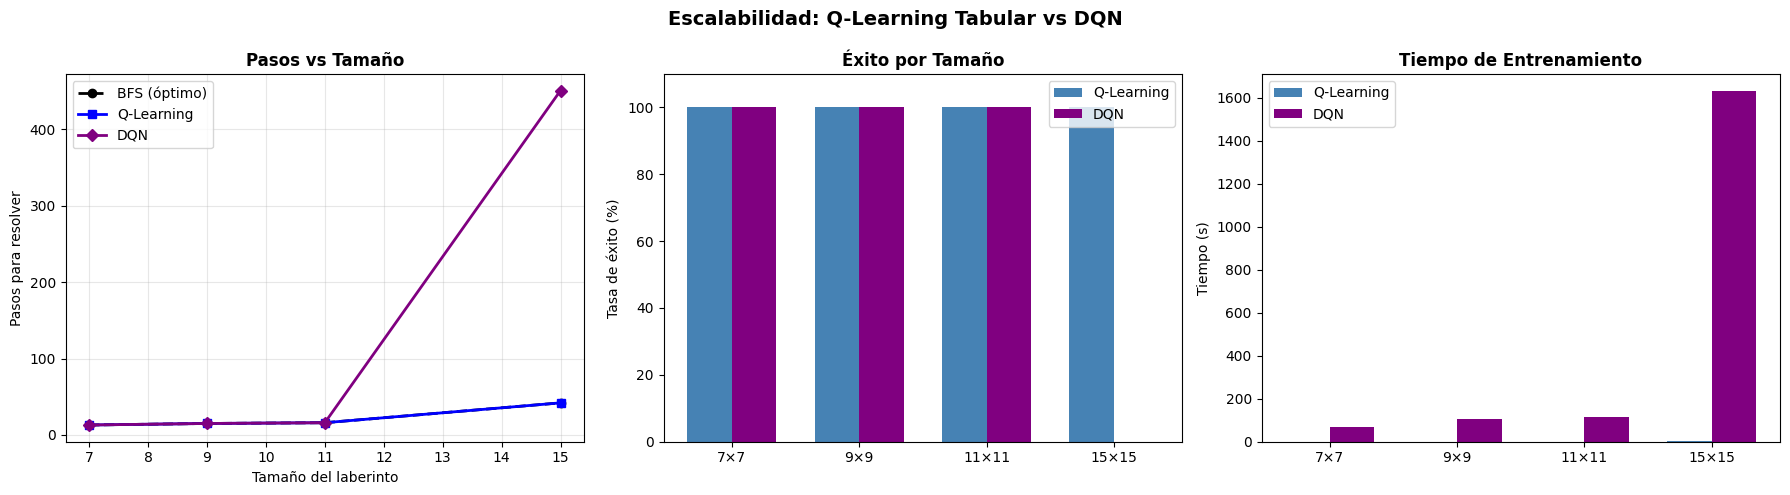

In [12]:
# --- Comparar métodos en diferentes tamaños ---
print("=" * 60)
print("COMPARACIÓN: ESCALABILIDAD POR TAMAÑO DE LABERINTO")
print("=" * 60)

tamanios_test = [7, 9, 11, 15]
resultados = {size: {} for size in tamanios_test}

for size in tamanios_test:
    print(f"\n--- Laberinto {size}×{size} ---")
    maze = Laberinto(size, size, seed=42)
    sol = maze.resolver_bfs()

    # Q-Learning
    aq = QLearningAgent(maze.n_estados, 4, alpha=0.2, gamma=0.99, epsilon_decay=0.997)
    start = time.time()
    aq.entrenar(maze, n_episodios=3000, verbose=False)
    t_q = time.time() - start
    cam_q, _, ev_q = aq.resolver(maze)
    tasa_q = np.mean(aq.exitos[-200:]) * 100

    # DQN
    sd = len(maze._get_estado_vector())
    adqn = AgenteDQN(sd, 4, lr=5e-4, epsilon_decay=0.997)
    start = time.time()
    adqn.entrenar(maze, n_episodios=1500, verbose=False)
    t_dqn = time.time() - start
    cam_dqn, _, ev_dqn = adqn.resolver(maze)
    tasa_dqn = np.mean(adqn.exitos[-200:]) * 100

    resultados[size] = {
        'optimo': len(sol),
        'q_pasos': len(cam_q), 'q_exito': tasa_q, 'q_tiempo': t_q, 'q_evento': ev_q,
        'dqn_pasos': len(cam_dqn), 'dqn_exito': tasa_dqn, 'dqn_tiempo': t_dqn, 'dqn_evento': ev_dqn,
    }

    print(f"  Óptimo: {len(sol)} pasos")
    print(f"  Q-Learn: {len(cam_q)} pasos, {tasa_q:.0f}% éxito, {t_q:.1f}s ({ev_q})")
    print(f"  DQN:     {len(cam_dqn)} pasos, {tasa_dqn:.0f}% éxito, {t_dqn:.1f}s ({ev_dqn})")

# Visualización
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sizes = list(resultados.keys())

# 1. Pasos vs tamaño
opt_steps = [resultados[s]['optimo'] for s in sizes]
q_steps = [resultados[s]['q_pasos'] for s in sizes]
dqn_steps = [resultados[s]['dqn_pasos'] for s in sizes]

axes[0].plot(sizes, opt_steps, 'k--o', label='BFS (óptimo)', linewidth=2)
axes[0].plot(sizes, q_steps, 'b-s', label='Q-Learning', linewidth=2)
axes[0].plot(sizes, dqn_steps, 'purple', marker='D', label='DQN', linewidth=2)
axes[0].set_xlabel('Tamaño del laberinto')
axes[0].set_ylabel('Pasos para resolver')
axes[0].set_title('Pasos vs Tamaño', fontweight='bold')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

# 2. Tasa de éxito
q_exitos = [resultados[s]['q_exito'] for s in sizes]
dqn_exitos = [resultados[s]['dqn_exito'] for s in sizes]

x = np.arange(len(sizes))
w = 0.35
axes[1].bar(x - w/2, q_exitos, w, label='Q-Learning', color='steelblue')
axes[1].bar(x + w/2, dqn_exitos, w, label='DQN', color='purple')
axes[1].set_xticks(x)
axes[1].set_xticklabels([f'{s}×{s}' for s in sizes])
axes[1].set_ylabel('Tasa de éxito (%)')
axes[1].set_title('Éxito por Tamaño', fontweight='bold')
axes[1].legend(); axes[1].set_ylim(0, 110)

# 3. Tiempo de entrenamiento
q_times = [resultados[s]['q_tiempo'] for s in sizes]
dqn_times = [resultados[s]['dqn_tiempo'] for s in sizes]

axes[2].bar(x - w/2, q_times, w, label='Q-Learning', color='steelblue')
axes[2].bar(x + w/2, dqn_times, w, label='DQN', color='purple')
axes[2].set_xticks(x)
axes[2].set_xticklabels([f'{s}×{s}' for s in sizes])
axes[2].set_ylabel('Tiempo (s)')
axes[2].set_title('Tiempo de Entrenamiento', fontweight='bold')
axes[2].legend()

plt.suptitle('Escalabilidad: Q-Learning Tabular vs DQN', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Resumen y Conclusiones

### Métodos implementados:

| Método | Tipo | Escalabilidad | Mejor para |
|--------|------|--------------|-----------|
| **Q-Learning** | Tabular, off-policy | Pequeños (≤15×15) | Laberintos simples, convergencia rápida |
| **SARSA** | Tabular, on-policy | Pequeños (≤15×15) | Entornos con trampas (más seguro) |
| **DQN** | Deep RL, off-policy | Grandes | Generalización, estados continuos |
| **REINFORCE** | Policy Gradient | Medios | Políticas estocásticas, acciones continuas |

### Lecciones aprendidas:

1. **Tabular vs Deep**: Q-Learning tabular es más rápido y estable para laberintos pequeños.
   DQN escala mejor cuando el espacio de estados crece.

2. **On-policy vs Off-policy**: SARSA (on-policy) es más conservador en entornos peligrosos.
   Q-Learning (off-policy) encuentra rutas más directas pero potencialmente arriesgadas.

3. **Exploración**: ε-greedy con decay es fundamental. Sin suficiente exploración,
   el agente se queda en soluciones subóptimas.

4. **Recompensas**: El diseño del reward shaping es crucial:
   - Penalización por paso → eficiencia
   - Recompensa por meta → objetivo
   - Penalización por paredes → evitar choques
   - Bonus intermedios → guiar al agente

5. **Representación del estado**: La vista local 5×5 + dirección a meta
   permite al DQN generalizar entre posiciones.

### ¿Cuándo usar cada método?

```
¿El espacio de estados es pequeño (<1000)?
│
├── Sí → Q-Learning / SARSA (tabular, rápido)
│        ├── ¿Hay peligros? → SARSA (conservador)
│        └── ¿Optimizar velocidad? → Q-Learning (agresivo)
│
└── No → Deep RL
         ├── ¿Acciones discretas? → DQN
         └── ¿Acciones continuas? → Policy Gradient / Actor-Critic
```